# 🧠📍 Smart Tagging

Metrica's **automatic** tactical annotation of the tactical video: phases of play and set
pieces, each one a time interval with a code and a set of tags.

This notebook covers loading it, what is in it, and the two things that will bite you if you
treat it as ground truth.

---

## Loading

The file is a **SportsCode XML**, the standard format in football performance analysis, so
[kloppy](https://kloppy.pysport.org/user-guide/loading-data/sportscode/) reads it directly.

`games.asset_paths()` builds the path, so nothing here spells a filename out and
`MTAH_DATA_DIR` keeps working if you store the bundle elsewhere.

In [1]:
%pip install kloppy pandas numpy

Note: you may need to restart the kernel to use updated packages.


## From now, before kick in, brake, and after finish of the game, everything is marked as Dead ball. In the end of the code we should mark it as X, because there is no game in that moment

In [2]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
from kloppy import sportscode
import games

path = games.asset_paths()["smart_tagging"]
events = sportscode.load(path).to_df()

game = games.GAME
fps = games.GAMES[game]["fps"]
n_frames = games.GAMES[game]["n_video_frames"]

halves = {
    half: (start, end)
    for half, start, end in games.half_video_blocks(game)
}
first_start, first_end = halves[1]
second_start, second_end = halves[2]

# The documented second-half kickoff anchor is the last frame before play starts.
second_kickoff = games.anchor_video_frame(
    games.GAMES[game]["kickoff_2nd"]
) + 1

# Ranges use an exclusive end frame, so each row ends exactly at the next section's start.
breaks = [
    ("Before first kickoff", 0, first_start),
    ("Halftime", first_end + 1, second_start),
    ("Before second-half kickoff", second_start, second_kickoff),
    ("After final whistle", second_end + 1, n_frames),
]

next_code_id = int(events["code_id"].max()) + 1
synthetic_rows = []

for label, start_frame, end_frame in breaks:
    row = {column: pd.NA for column in events.columns}
    row.update({
        "code_id": next_code_id,
        "timestamp": pd.to_timedelta(start_frame / fps, unit="s"),
        "end_timestamp": pd.to_timedelta(end_frame / fps, unit="s"),
        "code": "DEAD BALL",
        "Team": "N/A",
        "Type": label,
    })
    synthetic_rows.append(row)
    next_code_id += 1

events = pd.concat(
    [events, pd.DataFrame(synthetic_rows, columns=events.columns)],
    ignore_index=True,
).sort_values("timestamp").reset_index(drop=True)

print(f"{len(events)} events, including {len(breaks)} generated no-play intervals")
events.tail()

642 events, including 4 generated no-play intervals


,code_id,period_id,timestamp,end_timestamp,code,Team,Type,Half,Max Players in the box,Side,Direction of ball entry
637,449,1,0 days 02:05:37.280000,0 days 02:06:12.280000,SET PIECES,N/A,Throw-in,2nd Half,None,None,None
638,277,1,0 days 02:05:46.640000,0 days 02:06:09.440000,PROGRESSION,Atletic Club,None,2nd Half,None,None,None
639,501,1,0 days 02:05:46.640000,0 days 02:06:09.440000,DEFENDING IN MIDDLE THIRD,Barcelona,None,2nd Half,None,None,None
640,103,<NA>,0 days 02:06:47.920000,0 days 02:12:52.760000,DEAD BALL,N/A,After final whistle,<NA>,<NA>,<NA>,<NA>
641,103,1,0 days 02:07:58.600000,0 days 02:08:39.280000,PLAYERS IN THE BOX,Atletic Club,None,2nd Half,2,None,None


## Whats in smart tagging

In [3]:
events['code'].value_counts()

code
PLAYERS IN THE BOX              97
BALL IN FINAL THIRD             93
BALL IN THE BOX                 72
PROGRESSION                     66
DEFENDING IN MIDDLE THIRD       66
SET PIECES                      59
CREATING CHANCES                30
DEFENDING IN DEFENSIVE THIRD    30
LONG BALL                       29
DEFENSIVE TRANSITION            24
ATTACKING TRANSITION            24
BUILD UP                        22
DEFENDING IN ATTACKING THIRD    22
DEAD BALL                        4
GOALS                            4
Name: count, dtype: int64

## Ploting smart tagging + brakes

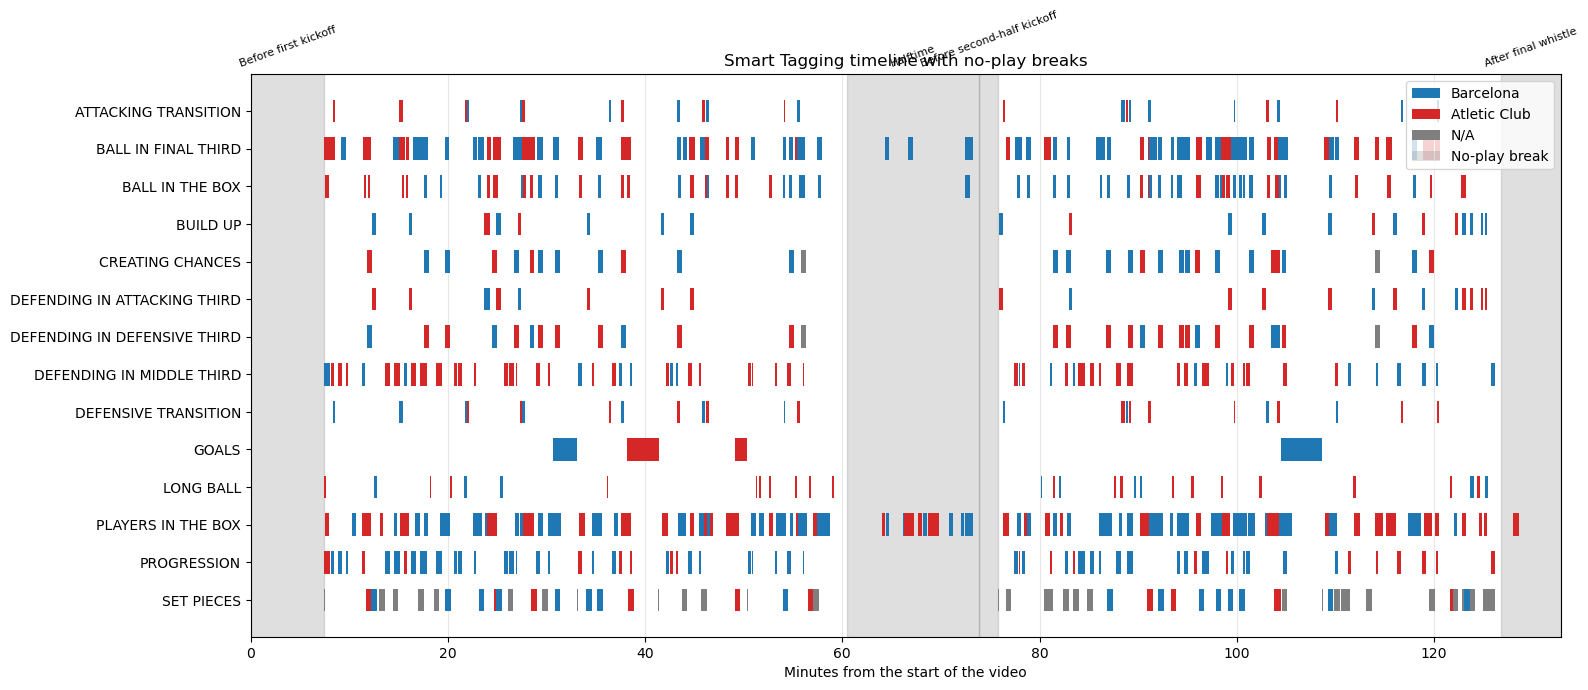

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

ev = events.copy()
ev["start_min"] = ev["timestamp"].dt.total_seconds() / 60
ev["end_min"] = ev["end_timestamp"].dt.total_seconds() / 60
ev["dur_min"] = ev["end_min"] - ev["start_min"]

# Generated break rows are identified by their code and their Type describes each break.
breaks = ev[ev["code"] == "DEAD BALL"]
tag_events = ev[ev["code"] != "DEAD BALL"]
codes = sorted(tag_events["code"].unique())

team_colour = {
    "Barcelona": "tab:blue",
    "Atletic Club": "tab:red",
    "N/A": "tab:gray",
}

fig, ax = plt.subplots(figsize=(16, 7))

# Shade breaks using the intervals stored in events.
for _, row in breaks.iterrows():
    ax.axvspan(row["start_min"], row["end_min"], color="gray", alpha=0.25, zorder=0)
    ax.text(
        (row["start_min"] + row["end_min"]) / 2,
        1.01,
        row["Type"],
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=8,
        rotation=20,
    )

# Plot Smart Tagging intervals.
for i, code in enumerate(codes):
    for _, row in tag_events[tag_events["code"] == code].iterrows():
        ax.barh(
            i,
            row["dur_min"],
            left=row["start_min"],
            height=0.6,
            color=team_colour.get(row["Team"], "tab:gray"),
            zorder=2,
        )

ax.set_xlim(0, ev["end_min"].max())
ax.set_yticks(range(len(codes)))
ax.set_yticklabels(codes)
ax.invert_yaxis()
ax.set_xlabel("Minutes from the start of the video")
ax.set_title("Smart Tagging timeline with no-play breaks")
ax.grid(axis="x", alpha=0.3)
ax.legend(
    handles=[
        Patch(facecolor="tab:blue", label="Barcelona"),
        Patch(facecolor="tab:red", label="Atletic Club"),
        Patch(facecolor="tab:gray", label="N/A"),
        Patch(facecolor="gray", alpha=0.25, label="No-play break"),
    ],
    loc="upper right",
)
plt.tight_layout()
plt.show()

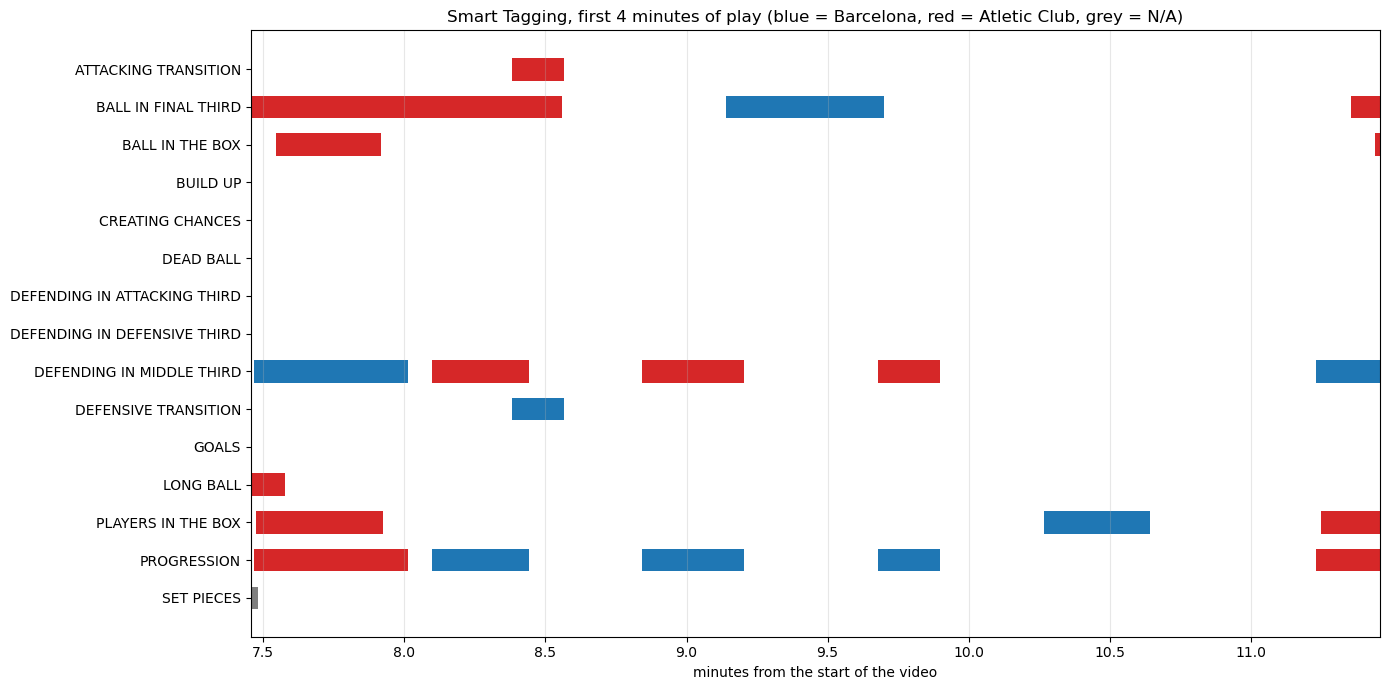

In [5]:
import matplotlib.pyplot as plt

KICKOFF_MIN = 11185 / 25 / 60       # first-half kick-off, about 7.46 minutes
WINDOW_START = KICKOFF_MIN
WINDOW_END = KICKOFF_MIN + 4        # first 4 minutes of play

ev = events.copy()
ev['start_min'] = ev['timestamp'].dt.total_seconds() / 60
ev['end_min'] = ev['end_timestamp'].dt.total_seconds() / 60
ev['dur_min'] = ev['end_min'] - ev['start_min']

# keep only tags that overlap the window
ev = ev[(ev['end_min'] >= WINDOW_START) & (ev['start_min'] <= WINDOW_END)]

codes = sorted(events['code'].unique())   # same row order for every window
team_colour = {'Barcelona': 'tab:blue', 'Atletic Club': 'tab:red', 'N/A': 'tab:gray'}

fig, ax = plt.subplots(figsize=(14, 7))
for i, code in enumerate(codes):
    for _, row in ev[ev['code'] == code].iterrows():
        ax.barh(i, row['dur_min'], left=row['start_min'], height=0.6,
                color=team_colour.get(row['Team'], 'tab:gray'))

ax.set_yticks(range(len(codes)))
ax.set_yticklabels(codes)
ax.invert_yaxis()
ax.set_xlim(WINDOW_START, WINDOW_END)
ax.set_xlabel('minutes from the start of the video')
ax.set_title('Smart Tagging, first 4 minutes of play (blue = Barcelona, red = Atletic Club, grey = N/A)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

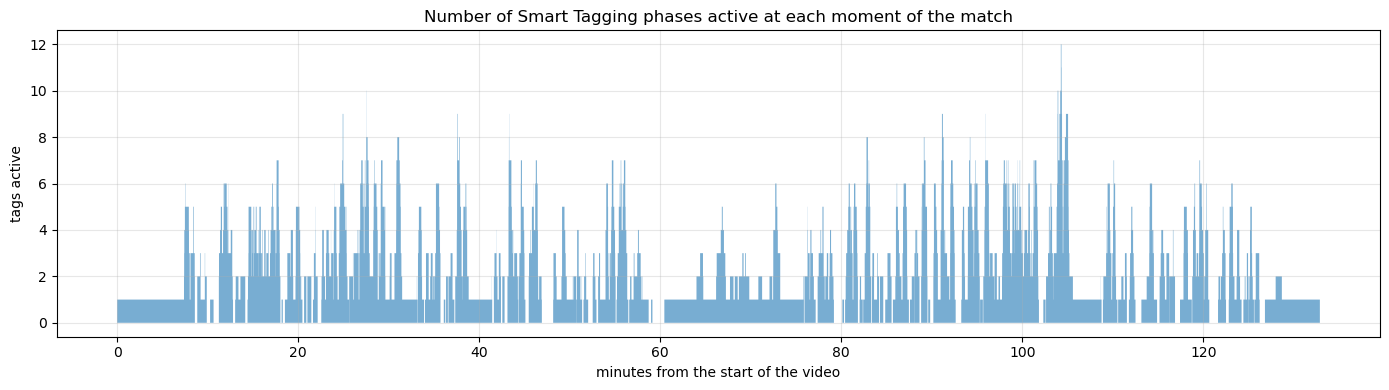

largest number of tags active at once: 12
overlapping pairs: 1838
overlapping pairs with different teams: 930


,start_min,code_a,team_a,code_b,team_b,overlap_s
835,66.17,DEAD BALL,N/A,PLAYERS IN THE BOX,Barcelona,51.3
846,72.47,DEAD BALL,N/A,PLAYERS IN THE BOX,Barcelona,46.6
1837,127.98,DEAD BALL,N/A,PLAYERS IN THE BOX,Atletic Club,40.7
853,66.23,PLAYERS IN THE BOX,Barcelona,PLAYERS IN THE BOX,Atletic Club,40.2
836,66.23,DEAD BALL,N/A,PLAYERS IN THE BOX,Atletic Club,40.2
192,18.80,DEFENDING IN MIDDLE THIRD,Atletic Club,PROGRESSION,Barcelona,37.1
1067,88.86,DEFENDING IN MIDDLE THIRD,Atletic Club,PROGRESSION,Barcelona,36.3
1597,104.57,BALL IN FINAL THIRD,Barcelona,SET PIECES,N/A,35.0
1603,104.57,GOALS,Barcelona,SET PIECES,N/A,35.0
1588,104.57,PLAYERS IN THE BOX,Barcelona,SET PIECES,N/A,35.0


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ev = events.copy()
ev['start_s'] = ev['timestamp'].dt.total_seconds()
ev['end_s'] = ev['end_timestamp'].dt.total_seconds()

# 1. How many tags are active at each second of the match
t = np.arange(0, ev['end_s'].max(), 1.0)
active = np.zeros_like(t)
for _, row in ev.iterrows():
    active[(t >= row['start_s']) & (t < row['end_s'])] += 1

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(t / 60, active, step='post', alpha=0.6)
ax.set_xlabel('minutes from the start of the video')
ax.set_ylabel('tags active')
ax.set_title('Number of Smart Tagging phases active at each moment of the match')
ax.grid(axis='both', alpha=0.3)
plt.tight_layout()
plt.show()

print('largest number of tags active at once:', int(active.max()))

# 2. Every pair of tags that overlap in time
rows = ev.sort_values('start_s').reset_index(drop=True)
pairs = []
for i in range(len(rows)):
    for j in range(i + 1, len(rows)):
        if rows.loc[j, 'start_s'] >= rows.loc[i, 'end_s']:
            break   # rows are sorted by start, so no later row can overlap row i
        overlap_s = min(rows.loc[i, 'end_s'], rows.loc[j, 'end_s']) - rows.loc[j, 'start_s']
        pairs.append({
            'start_min': round(rows.loc[j, 'start_s'] / 60, 2),
            'code_a': rows.loc[i, 'code'], 'team_a': rows.loc[i, 'Team'],
            'code_b': rows.loc[j, 'code'], 'team_b': rows.loc[j, 'Team'],
            'overlap_s': round(overlap_s, 1),
        })

overlaps = pd.DataFrame(pairs)
print('overlapping pairs:', len(overlaps))

# Pairs where the two tags belong to different teams are the most informative
conflicts = overlaps[overlaps['team_a'] != overlaps['team_b']]
print('overlapping pairs with different teams:', len(conflicts))
conflicts.sort_values('overlap_s', ascending=False).head(20)

In [7]:
import numpy as np
import pandas as pd

ev = events.reset_index(drop=True)
s = ev['timestamp'].dt.total_seconds().to_numpy()
e = ev['end_timestamp'].dt.total_seconds().to_numpy()
code = ev['code'].to_numpy()
team = ev['Team'].to_numpy()

# 1. For each tag, find the opposite-team tag whose time span overlaps it most
records = []
for i in range(len(ev)):
    inter = np.minimum(e[i], e) - np.maximum(s[i], s)
    union = np.maximum(e[i], e) - np.minimum(s[i], s)
    iou = np.where(union > 0, inter / union, 0.0)   # 1.0 = identical time span
    valid = (code != code[i]) & (team != team[i]) & (team != 'N/A') & (team[i] != 'N/A')
    if not valid.any():
        continue
    iou = np.where(valid, iou, -1.0)
    j = int(np.argmax(iou))
    records.append({
        'code_a': code[i], 'team_a': team[i],
        'code_b': code[j], 'team_b': team[j],
        'best_iou': round(iou[j], 2),
    })

best = pd.DataFrame(records)

# 2. For each pair of codes, the share of code_a tags that mirror code_b (IoU >= 0.7)
best['mirrored'] = best['best_iou'] >= 0.7
mirrored = (best[best['mirrored']]
            .groupby(['code_a', 'code_b']).size()
            .rename('mirrored_count').reset_index())
totals = best.groupby('code_a').size().rename('total_a').reset_index()
summary = mirrored.merge(totals, on='code_a')
summary['share'] = (summary['mirrored_count'] / summary['total_a']).round(2)

summary.sort_values('share', ascending=False).head(20)

,code_a,code_b,mirrored_count,total_a,share
0,ATTACKING TRANSITION,DEFENSIVE TRANSITION,24,24,1.00
9,BUILD UP,DEFENDING IN ATTACKING THIRD,22,22,1.00
19,PROGRESSION,DEFENDING IN MIDDLE THIRD,66,66,1.00
14,DEFENSIVE TRANSITION,ATTACKING TRANSITION,24,24,1.00
13,DEFENDING IN MIDDLE THIRD,PROGRESSION,66,66,1.00
12,DEFENDING IN DEFENSIVE THIRD,CREATING CHANCES,28,28,1.00
10,CREATING CHANCES,DEFENDING IN DEFENSIVE THIRD,28,28,1.00
11,DEFENDING IN ATTACKING THIRD,BUILD UP,22,22,1.00
21,SET PIECES,DEFENDING IN DEFENSIVE THIRD,8,27,0.30
2,BALL IN FINAL THIRD,DEFENDING IN DEFENSIVE THIRD,21,93,0.23


## Reducing dependent variables

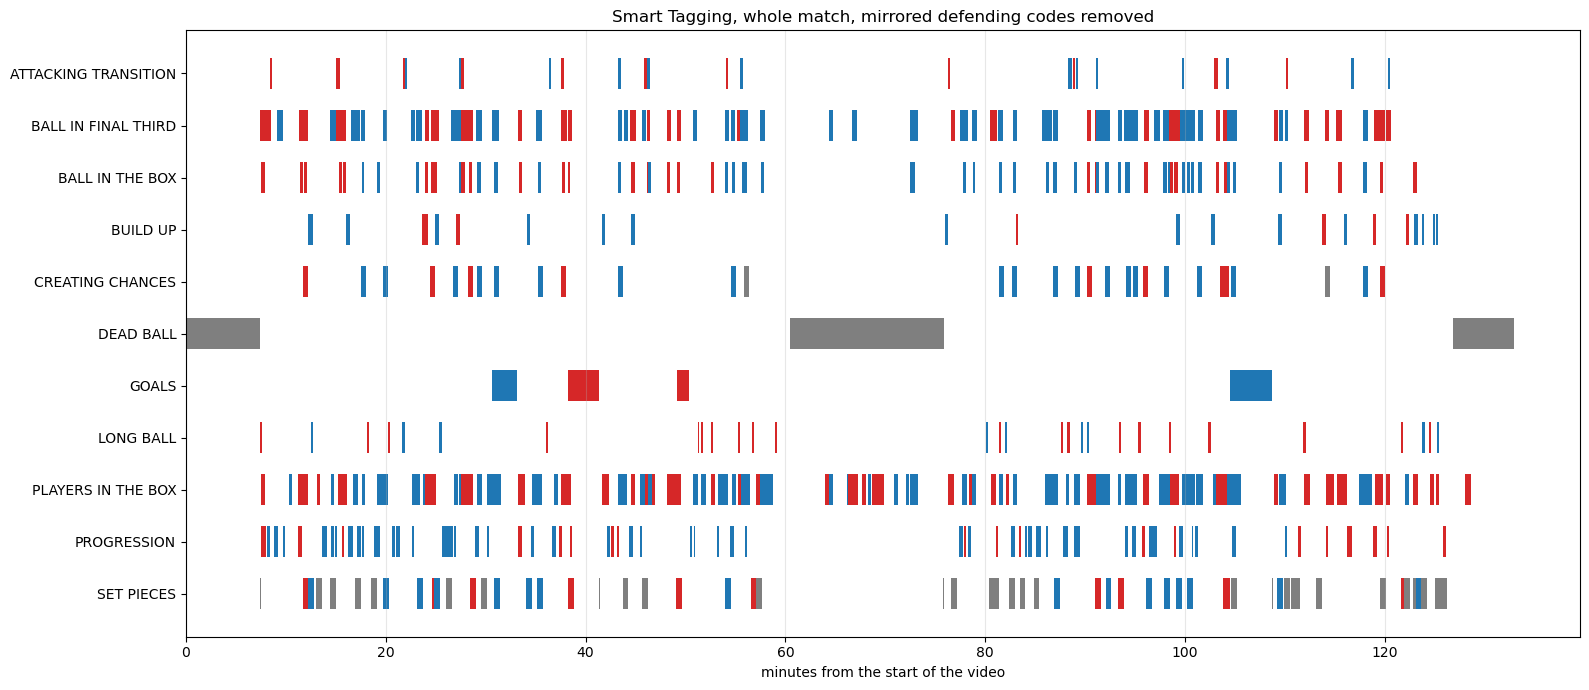

tags kept: 500 of 642


In [8]:
import numpy as np
import matplotlib.pyplot as plt

# One side of each mirror pair. Keep the attacking side, because its Team is the team in possession.
DROP_MIRRORS = [
    'DEFENDING IN MIDDLE THIRD',     # mirror of PROGRESSION
    'DEFENSIVE TRANSITION',          # mirror of ATTACKING TRANSITION
    'DEFENDING IN ATTACKING THIRD',  # mirror of BUILD UP
    'DEFENDING IN DEFENSIVE THIRD',  # mirror of CREATING CHANCES
]

ev = events[~events['code'].isin(DROP_MIRRORS)].copy()
ev['start_min'] = ev['timestamp'].dt.total_seconds() / 60
ev['dur_min'] = (ev['end_timestamp'] - ev['timestamp']).dt.total_seconds() / 60

codes = sorted(ev['code'].unique())
team_colour = {'Barcelona': 'tab:blue', 'Atletic Club': 'tab:red', 'N/A': 'tab:gray'}

fig, ax = plt.subplots(figsize=(16, 7))
for i, code in enumerate(codes):
    for _, row in ev[ev['code'] == code].iterrows():
        ax.barh(i, row['dur_min'], left=row['start_min'], height=0.6,
                color=team_colour.get(row['Team'], 'tab:gray'))

ax.set_yticks(range(len(codes)))
ax.set_yticklabels(codes)
ax.invert_yaxis()
ax.set_xlabel('minutes from the start of the video')
ax.set_title('Smart Tagging, whole match, mirrored defending codes removed')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print('tags kept:', len(ev), 'of', len(events))

## Viterbi Alghoritm on ATD, which prefer D on goals and corners, free kicks, throw-ins, goal kicks, and kick-offs

Creating viterbi with different biases toward D on 'set pices'

In [10]:
import numpy as np
import pandas as pd
from pathlib import Path
from kloppy import sportscode
import games
import baseline

FPS = 25
STATES = np.array(["H", "A", "D"])

# Nearest-player labels per frame: 0 = home, 1 = away, -1 = no answer
codes = baseline.build()
n = len(codes)
paths = games.asset_paths()

# Find Smart Tagging set-piece and goal intervals.
tags = sportscode.load(paths["smart_tagging"]).to_df()
restarts = tags[tags["code"].isin(["SET PIECES", "GOALS"])]

restart_window = np.zeros(n, dtype=bool)
for _, row in restarts.iterrows():
    start = max(int(round(row["timestamp"].total_seconds() * FPS)), 0)
    end = min(int(round(row["end_timestamp"].total_seconds() * FPS)), n)
    if start < end:
        restart_window[start:end] = True

# Base ATD emissions. Lower cost means a state is more favored.
base_emit = np.zeros((n, 3))
base_emit[codes == 0] = [0.0, 1.0, 1.0]  # ATD says home
base_emit[codes == 1] = [1.0, 0.0, 1.0]  # ATD says away

# Mark intervals explicitly labeled DEAD BALL in the events DataFrame.
no_play_window = np.zeros(n, dtype=bool)
no_play = events[events["code"] == "DEAD BALL"]

for _, row in no_play.iterrows():
    start = max(int(round(row["timestamp"].total_seconds() * FPS)), 0)
    end = min(int(round(row["end_timestamp"].total_seconds() * FPS)), n)
    if start < end:
        no_play_window[start:end] = True

def make_trans(switch_cost, dead_ball_cost):
    return np.array([
        [0.0, switch_cost, dead_ball_cost],
        [switch_cost, 0.0, dead_ball_cost],
        [dead_ball_cost, dead_ball_cost, 0.0],
    ])

def viterbi(emit, trans):
    T = emit.shape[0]
    cost = emit[0].copy()
    back = np.zeros((T, 3), dtype=np.int8)

    for t in range(1, T):
        candidates = cost[:, None] + trans
        back[t] = np.argmin(candidates, axis=0)
        cost = candidates[back[t], np.arange(3)] + emit[t]

    path = np.zeros(T, dtype=np.int8)
    path[-1] = np.argmin(cost)

    for t in range(T - 1, 0, -1):
        path[t - 1] = back[t, path[t]]

    return path

# Existing transition costs.
SWITCH = 20.0
TO_DEAD = 15.0
trans = make_trans(SWITCH, TO_DEAD)

# The blend weight controls how strongly set-piece/goal intervals favor D.
# Each value is applied independently to the same base ATD emissions.
restart_emission = np.array([2.0, 2.0, 0.0])
biases = {
    "low": 0.10,
    "medium": 0.25,
    "high": 0.50,
    "ultra_high": 1.00,
}

results_dir = Path("../evaluation/results")

for name, bias in biases.items():
    emit = base_emit.copy()

    emit[restart_window] = (
        (1.0 - bias) * base_emit[restart_window]
        + bias * restart_emission
    )

    # Keep explicitly marked dead-ball intervals strongly assigned to D.
    emit[no_play_window] = [1e6, 1e6, 0.0]

    labels = STATES[viterbi(emit, trans)]
    out = results_dir / f"my_hmm_v3_setpiece_bias_{name}.csv"

    pd.DataFrame({
        "frame": np.arange(n),
        "label": labels,
    }).to_csv(out, index=False)

    print(
        f"{name} bias ({bias:.0%}): saved {out} | "
        f"D share: {np.mean(labels == 'D'):.1%}"
    )

teams: H = Barcelona, A = Atletic Club
reading BAR-ATH_tactical_atd.txt ...
  ball located on 113488 of 199319 frames (56.9%)

low bias (10%): saved ../evaluation/results/my_hmm_v3_setpiece_bias_low.csv | D share: 35.3%
medium bias (25%): saved ../evaluation/results/my_hmm_v3_setpiece_bias_medium.csv | D share: 37.8%
high bias (50%): saved ../evaluation/results/my_hmm_v3_setpiece_bias_high.csv | D share: 50.6%
ultra_high bias (100%): saved ../evaluation/results/my_hmm_v3_setpiece_bias_ultra_high.csv | D share: 50.6%


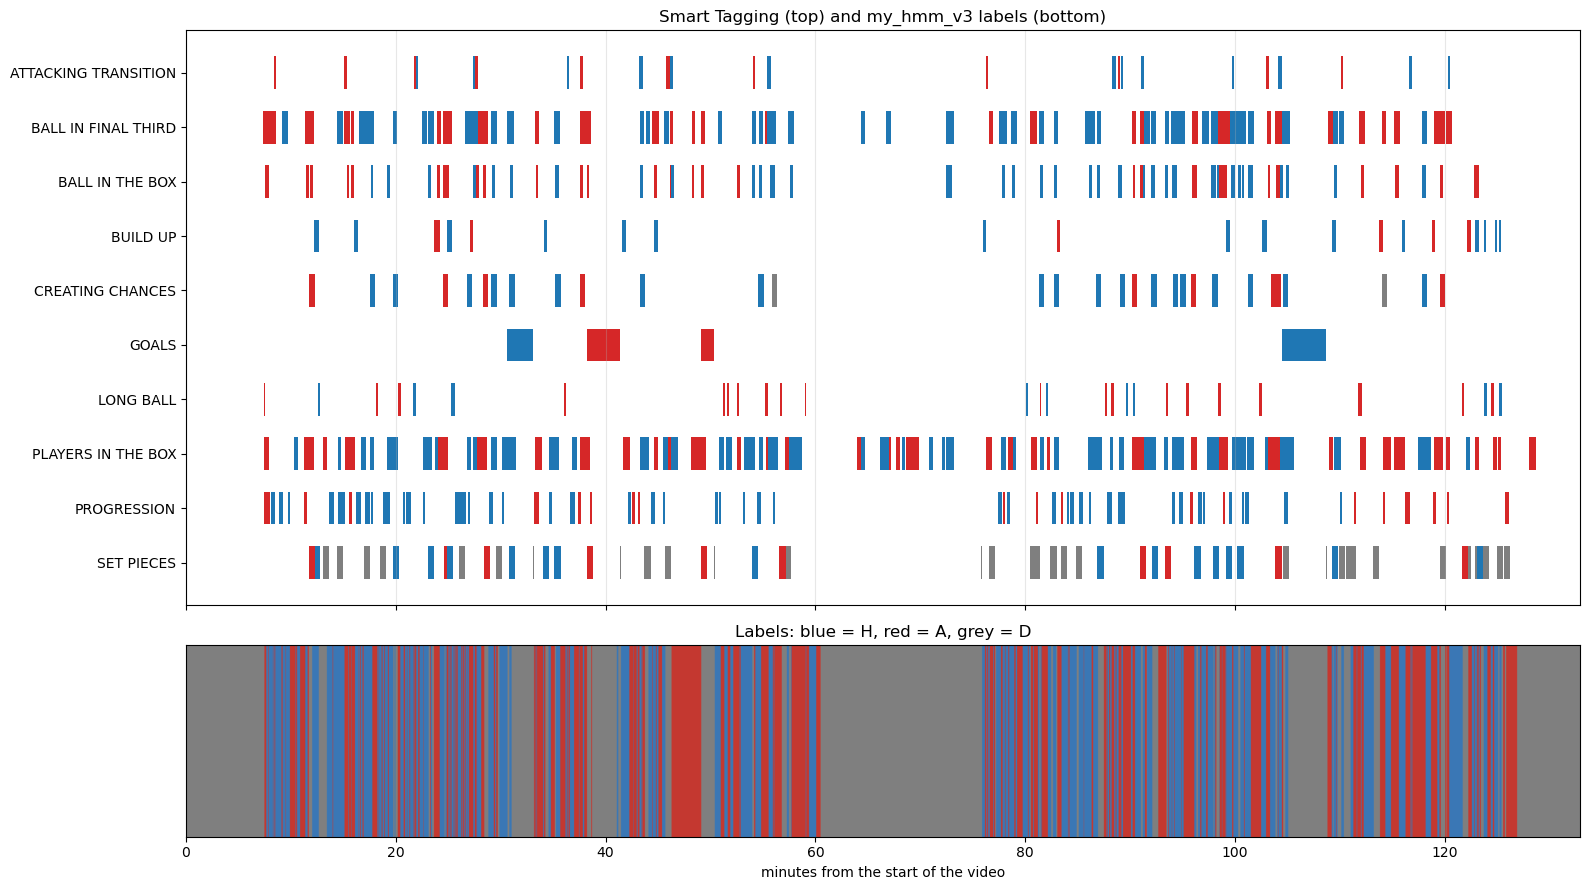

label counts: {'D': 75326, 'H': 67477, 'A': 56516}


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from kloppy import sportscode
import games

# Smart Tagging, with the mirrored defending codes removed
paths = games.asset_paths()
tags = sportscode.load(paths['smart_tagging']).to_df()

DROP_MIRRORS = ['DEFENDING IN MIDDLE THIRD', 'DEFENSIVE TRANSITION',
                'DEFENDING IN ATTACKING THIRD', 'DEFENDING IN DEFENSIVE THIRD']
ev = tags[~tags['code'].isin(DROP_MIRRORS)].copy()
ev['start_min'] = ev['timestamp'].dt.total_seconds() / 60
ev['dur_min'] = (ev['end_timestamp'] - ev['timestamp']).dt.total_seconds() / 60

team_colour = {'Barcelona': 'tab:blue', 'Atletic Club': 'tab:red', 'N/A': 'tab:gray'}

# The v3 labels, read from the file so the plot can't show another version by mistake
labels = pd.read_csv('../evaluation/results/my_hmm_v3_setpiece_bias_medium.csv')['label'].to_numpy()
n = len(labels)
total_min = n / 25 / 60

# One colour per second for the label strip
step = 25
colour = {'H': (0.23, 0.47, 0.71), 'A': (0.77, 0.22, 0.19), 'D': (0.5, 0.5, 0.5)}
strip = np.array([colour[x] for x in labels[::step]])[None, :, :]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})

# Top: the tags
codes_plot = sorted(ev['code'].unique())
for i, c in enumerate(codes_plot):
    for _, r in ev[ev['code'] == c].iterrows():
        ax1.barh(i, r['dur_min'], left=r['start_min'], height=0.6,
                 color=team_colour.get(r['Team'], 'tab:gray'))
ax1.set_yticks(range(len(codes_plot)))
ax1.set_yticklabels(codes_plot)
ax1.invert_yaxis()
ax1.set_title('Smart Tagging (top) and my_hmm_v3 labels (bottom)')
ax1.grid(axis='x', alpha=0.3)

# Bottom: the labels
ax2.imshow(strip, aspect='auto', extent=[0, total_min, 0, 1])
ax2.set_yticks([])
ax2.set_xlabel('minutes from the start of the video')
ax2.set_title('Labels: blue = H, red = A, grey = D')

plt.tight_layout()
plt.show()

print('label counts:', pd.Series(labels).value_counts().to_dict())

In [12]:
import glob, os
import numpy as np
import pandas as pd

FPS = 25
files = sorted(glob.glob('../evaluation/results/*.csv'))
labels = {}
for f in files:
    name = os.path.splitext(os.path.basename(f))[0]
    if name == 'my_hmm_v3_trace':
        continue
    df = pd.read_csv(f)
    labels[name] = df.sort_values('frame')['label'].to_numpy()

n = min(len(v) for v in labels.values())
labels = {k: v[:n] for k, v in labels.items()}

def possessions(lab):
    """Count H/A runs, ignoring D frames, and their mean length in seconds."""
    team = lab[lab != 'D']
    if len(team) == 0:
        return 0, 0.0
    changes = np.r_[True, team[1:] != team[:-1]]
    runs = np.diff(np.r_[np.flatnonzero(changes), len(team)])
    return len(runs), runs.mean() / FPS

rows = []
for name, lab in labels.items():
    poss, mean_s = possessions(lab)
    rows.append({
        'model': name,
        'H %': (lab == 'H').mean() * 100,
        'A %': (lab == 'A').mean() * 100,
        'D %': (lab == 'D').mean() * 100,
        'possessions': poss,
        'mean length s': mean_s,
    })
summary = pd.DataFrame(rows).round(1)
print(summary.to_string(index=False))

# Frame-by-frame agreement between every pair
names = list(labels)
agree = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        agree.loc[a, b] = (labels[a] == labels[b]).mean() * 100
print("\nframe agreement (%):")
print(agree.round(1).to_string())

                             model  H %  A %  D %  possessions  mean length s
                      baseline_raw 32.1 24.8 43.1         2152            2.1
                baseline_smooth125 41.5 31.2 27.3          380           15.3
                 baseline_smooth25 34.8 25.7 39.4          766            6.3
                 baseline_smooth50 36.6 27.5 35.9          584            8.8
                          my_first 32.1 24.8 43.1         2152            2.1
                         my_hmm_v1 55.8 44.2  0.0          902            8.8
                         my_hmm_v2 38.0 32.5 29.5         1260            4.5
                         my_hmm_v3 38.0 33.1 28.9          302           18.8
      my_hmm_v3_setpiece_bias_high 25.6 23.8 50.6          237           16.6
       my_hmm_v3_setpiece_bias_low 35.2 29.5 35.3          323           16.0
    my_hmm_v3_setpiece_bias_medium 33.9 28.4 37.8          297           16.7
my_hmm_v3_setpiece_bias_ultra_high 25.6 23.8 50.6          237  

In [13]:
import glob, os
import numpy as np
import pandas as pd

gt = pd.read_csv('../evaluation/gt/BAR-ATH_possession_gt_public.csv')
gt = gt[gt['label'].isin(['H', 'A', 'D'])][['frame', 'label']].rename(columns={'label': 'gt'})
gt_share = gt['gt'].value_counts(normalize=True).mul(100)

def macro_f1(y, p, classes=('H', 'A', 'D')):
    f1s = []
    for c in classes:
        tp = np.sum((y == c) & (p == c))
        fp = np.sum((y != c) & (p == c))
        fn = np.sum((y == c) & (p != c))
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        f1s.append(2 * prec * rec / (prec + rec) if prec + rec else 0.0)
    return np.mean(f1s)

rows = []
for f in sorted(glob.glob('../evaluation/results/*.csv')):
    name = os.path.splitext(os.path.basename(f))[0]
    if name == 'my_hmm_v3_trace':
        continue
    pred = pd.read_csv(f)[['frame', 'label']].rename(columns={'label': 'pred'})
    m = gt.merge(pred, on='frame', how='left')
    y = m['gt'].to_numpy()
    p = m['pred'].fillna('X').to_numpy()
    shares = {c: (p == c).mean() * 100 for c in ['H', 'A', 'D']}
    rows.append({
        'model': name,
        'H %': shares['H'], 'A %': shares['A'], 'D %': shares['D'],
        'gap H': shares['H'] - gt_share['H'],
        'gap A': shares['A'] - gt_share['A'],
        'gap D': shares['D'] - gt_share['D'],
        'accuracy %': (y == p).mean() * 100,
        'macro F1': macro_f1(y, p),
    })

print("ground truth: H", round(gt_share['H'], 1), " A", round(gt_share['A'], 1),
      " D", round(gt_share['D'], 1))
print(pd.DataFrame(rows).sort_values('macro F1', ascending=False).round(2).to_string(index=False))

ground truth: H 46.1  A 34.4  D 19.6
                             model   H %   A %   D %  gap H  gap A  gap D  accuracy %  macro F1
                         my_hmm_v3 50.37 33.77 15.85   4.32  -0.59  -3.73       69.39      0.66
      my_hmm_v3_setpiece_bias_high 50.37 33.77 15.85   4.32  -0.59  -3.73       69.39      0.66
my_hmm_v3_setpiece_bias_ultra_high 50.37 33.77 15.85   4.32  -0.59  -3.73       69.39      0.66
                 baseline_smooth50 58.16 35.47  6.37  12.11   1.11 -13.21       71.32      0.62
                 baseline_smooth25 57.15 33.81  9.04  11.09  -0.55 -10.55       69.12      0.62
       my_hmm_v3_setpiece_bias_low 59.80 36.27  3.93  13.75   1.91 -15.65       70.68      0.61
                         my_hmm_v2 51.13 31.83 17.04   5.08  -2.53  -2.55       62.95      0.60
    my_hmm_v3_setpiece_bias_medium 59.28 34.24  6.48  13.23  -0.12 -13.11       68.97      0.60
                      baseline_raw 54.55 33.65 11.80   8.49  -0.71  -7.79       65.12      0.60
   

## combining ATD results with smart tagging

Creating CSV file with analyzed whole match with smart tagging + viterbi


## Combinig baseline_smooth125 with my_hmm_v3 and brakes

In [15]:
from pathlib import Path

import pandas as pd

results_dir = Path("../evaluation/results")

hmm_files = {
    "low": results_dir / "my_hmm_v3_setpiece_bias_low.csv",
    "medium": results_dir / "my_hmm_v3_setpiece_bias_medium.csv",
    "high": results_dir / "my_hmm_v3_setpiece_bias_high.csv",
    "ultra_high": results_dir / "my_hmm_v3_setpiece_bias_ultra_high.csv",
}

baseline_files = {
    "raw": results_dir / "baseline_raw.csv",
    "smooth25": results_dir / "baseline_smooth25.csv",
    "smooth50": results_dir / "baseline_smooth50.csv",
    "smooth125": results_dir / "baseline_smooth125.csv",
}

for hmm_name, hmm_path in hmm_files.items():
    hmm = pd.read_csv(hmm_path)

    if not {"frame", "label"}.issubset(hmm.columns):
        raise ValueError(f"{hmm_path} must contain 'frame' and 'label' columns.")
    if hmm["frame"].duplicated().any():
        raise ValueError(f"{hmm_path} contains duplicate frame numbers.")

    hmm_labels = hmm.set_index("frame")["label"]

    for baseline_name, baseline_path in baseline_files.items():
        baseline = pd.read_csv(baseline_path)

        if not {"frame", "label"}.issubset(baseline.columns):
            raise ValueError(
                f"{baseline_path} must contain 'frame' and 'label' columns."
            )
        if baseline["frame"].duplicated().any():
            raise ValueError(f"{baseline_path} contains duplicate frame numbers.")

        if set(baseline["frame"]) != set(hmm_labels.index):
            raise ValueError(
                f"{baseline_path} and {hmm_path} do not contain the same frames."
            )

        # Keep baseline labels, except where this HMM predicts D.
        aligned_hmm_labels = hmm_labels.reindex(baseline["frame"])
        result = baseline.copy()
        result["label"] = result["label"].where(
            aligned_hmm_labels.to_numpy() != "D",
            "D",
        )

        out_path = (
            results_dir
            / f"baseline_{baseline_name}_with_hmm_setpiece_bias_{hmm_name}_D.csv"
        )
        result.to_csv(out_path, index=False)

        print(
            f"Saved {len(result)} frames: "
            f"{baseline_name} baseline + {hmm_name} HMM D → {out_path}"
        )

Saved 199319 frames: raw baseline + low HMM D → ../evaluation/results/baseline_raw_with_hmm_setpiece_bias_low_D.csv
Saved 199319 frames: smooth25 baseline + low HMM D → ../evaluation/results/baseline_smooth25_with_hmm_setpiece_bias_low_D.csv
Saved 199319 frames: smooth50 baseline + low HMM D → ../evaluation/results/baseline_smooth50_with_hmm_setpiece_bias_low_D.csv
Saved 199319 frames: smooth125 baseline + low HMM D → ../evaluation/results/baseline_smooth125_with_hmm_setpiece_bias_low_D.csv
Saved 199319 frames: raw baseline + medium HMM D → ../evaluation/results/baseline_raw_with_hmm_setpiece_bias_medium_D.csv
Saved 199319 frames: smooth25 baseline + medium HMM D → ../evaluation/results/baseline_smooth25_with_hmm_setpiece_bias_medium_D.csv
Saved 199319 frames: smooth50 baseline + medium HMM D → ../evaluation/results/baseline_smooth50_with_hmm_setpiece_bias_medium_D.csv
Saved 199319 frames: smooth125 baseline + medium HMM D → ../evaluation/results/baseline_smooth125_with_hmm_setpiece_bi

In [16]:
import os
import sys

sys.path.insert(0, os.path.abspath("../evaluation"))
import possession_metrics as pm

gt = pm.read_label_csv("../evaluation/gt/BAR-ATH_possession_gt_public.csv")
gt_codes = pm.label_codes(gt)
scored = gt_codes < pm.N_SCORED
n_scored = int(scored.sum())

results_dir = "../evaluation/results"

files = {
    # Baseline predictions
    "Baseline raw": f"{results_dir}/baseline_raw.csv",
    "Baseline smooth25": f"{results_dir}/baseline_smooth25.csv",
    "Baseline smooth50": f"{results_dir}/baseline_smooth50.csv",
    "Baseline smooth125": f"{results_dir}/baseline_smooth125.csv",

    # HMM variants with different set-piece/goal biases
    "HMM set-piece low": f"{results_dir}/my_hmm_v3_setpiece_bias_low.csv",
    "HMM set-piece medium": f"{results_dir}/my_hmm_v3_setpiece_bias_medium.csv",
    "HMM set-piece high": f"{results_dir}/my_hmm_v3_setpiece_bias_high.csv",
    "HMM set-piece ultra high": f"{results_dir}/my_hmm_v3_setpiece_bias_ultra_high.csv",
}

# Baseline + HMM-D combinations: retain baseline labels except where HMM predicts D.
baseline_names = ["raw", "smooth25", "smooth50", "smooth125"]
hmm_biases = ["low", "medium", "high", "ultra_high"]

for baseline_name in baseline_names:
    for bias in hmm_biases:
        name = f"Baseline {baseline_name} + HMM {bias} D"
        path = (
            f"{results_dir}/baseline_{baseline_name}"
            f"_with_hmm_setpiece_bias_{bias}_D.csv"
        )
        files[name] = path

missing = [path for path in files.values() if not os.path.isfile(path)]
if missing:
    raise FileNotFoundError(
        "These prediction files are missing. Run the cells that generate them first:\n"
        + "\n".join(missing)
    )

print(f"Scored frames: {n_scored}")
print(
    f"{'Model':<40} {'H %':>7} {'A %':>7} {'D %':>7} "
    f"{'Accuracy':>10} {'Macro F1':>10} {'Spell F1':>10}"
)

for name, path in files.items():
    prediction = pm.read_label_csv(path)
    error = pm.validate_submission(prediction, len(gt_codes))
    if error:
        raise ValueError(f"{name}: {error}")

    scores = pm.evaluate(
        gt_codes,
        pm.label_codes(prediction),
        bootstrap_n=0,
    )

    # Percentages are calculated only over frames with public ground truth.
    pred = (
        prediction["label"]
        .astype(str)
        .str.strip()
        .str.upper()
        .to_numpy()[scored]
    )
    percentages = {
        label: (pred == label).mean() * 100
        for label in ("H", "A", "D")
    }

    print(
        f"{name:<40} "
        f"{percentages['H']:6.1f}% "
        f"{percentages['A']:6.1f}% "
        f"{percentages['D']:6.1f}% "
        f"{scores['accuracy'] * 100:9.2f}% "
        f"{scores['macro_f1']:10.4f} "
        f"{scores['spell_f1_mean']:10.4f}"
    )

Scored frames: 7500
Model                                        H %     A %     D %   Accuracy   Macro F1   Spell F1
Baseline raw                               54.5%   33.7%   11.8%     65.12%     0.5972     0.0378
Baseline smooth25                          57.1%   33.8%    9.0%     69.12%     0.6200     0.2868
Baseline smooth50                          58.2%   35.5%    6.4%     71.32%     0.6207     0.3256
Baseline smooth125                         61.5%   36.9%    1.5%     72.75%     0.5812     0.4242
HMM set-piece low                          59.8%   36.3%    3.9%     70.68%     0.6147     0.3368
HMM set-piece medium                       59.3%   34.2%    6.5%     68.97%     0.5985     0.3027
HMM set-piece high                         50.4%   33.8%   15.9%     69.39%     0.6551     0.2778
HMM set-piece ultra high                   50.4%   33.8%   15.9%     69.39%     0.6551     0.2778
Baseline raw + HMM low D                   54.5%   33.7%   11.8%     65.12%     0.5972     0.0378


## !!! How to pick correct alghoritm? !!!

those are banchmarks for baseline evaluated on WHOLE MATCH.
baseline smooth125 performs badly on whole match, but perform excelent on first 5 minutes

| baseline | macroF1 | spellF1 |
|---|---|---|
| `baseline_raw` | 0.6532 | 0.0486 |
| `baseline_smooth25` | **0.6752** | 0.1996 |
| `baseline_smooth50` | 0.6724 | **0.2433** |
| `baseline_smooth125` | 0.6356 | 0.2242 |

## Ploting all models

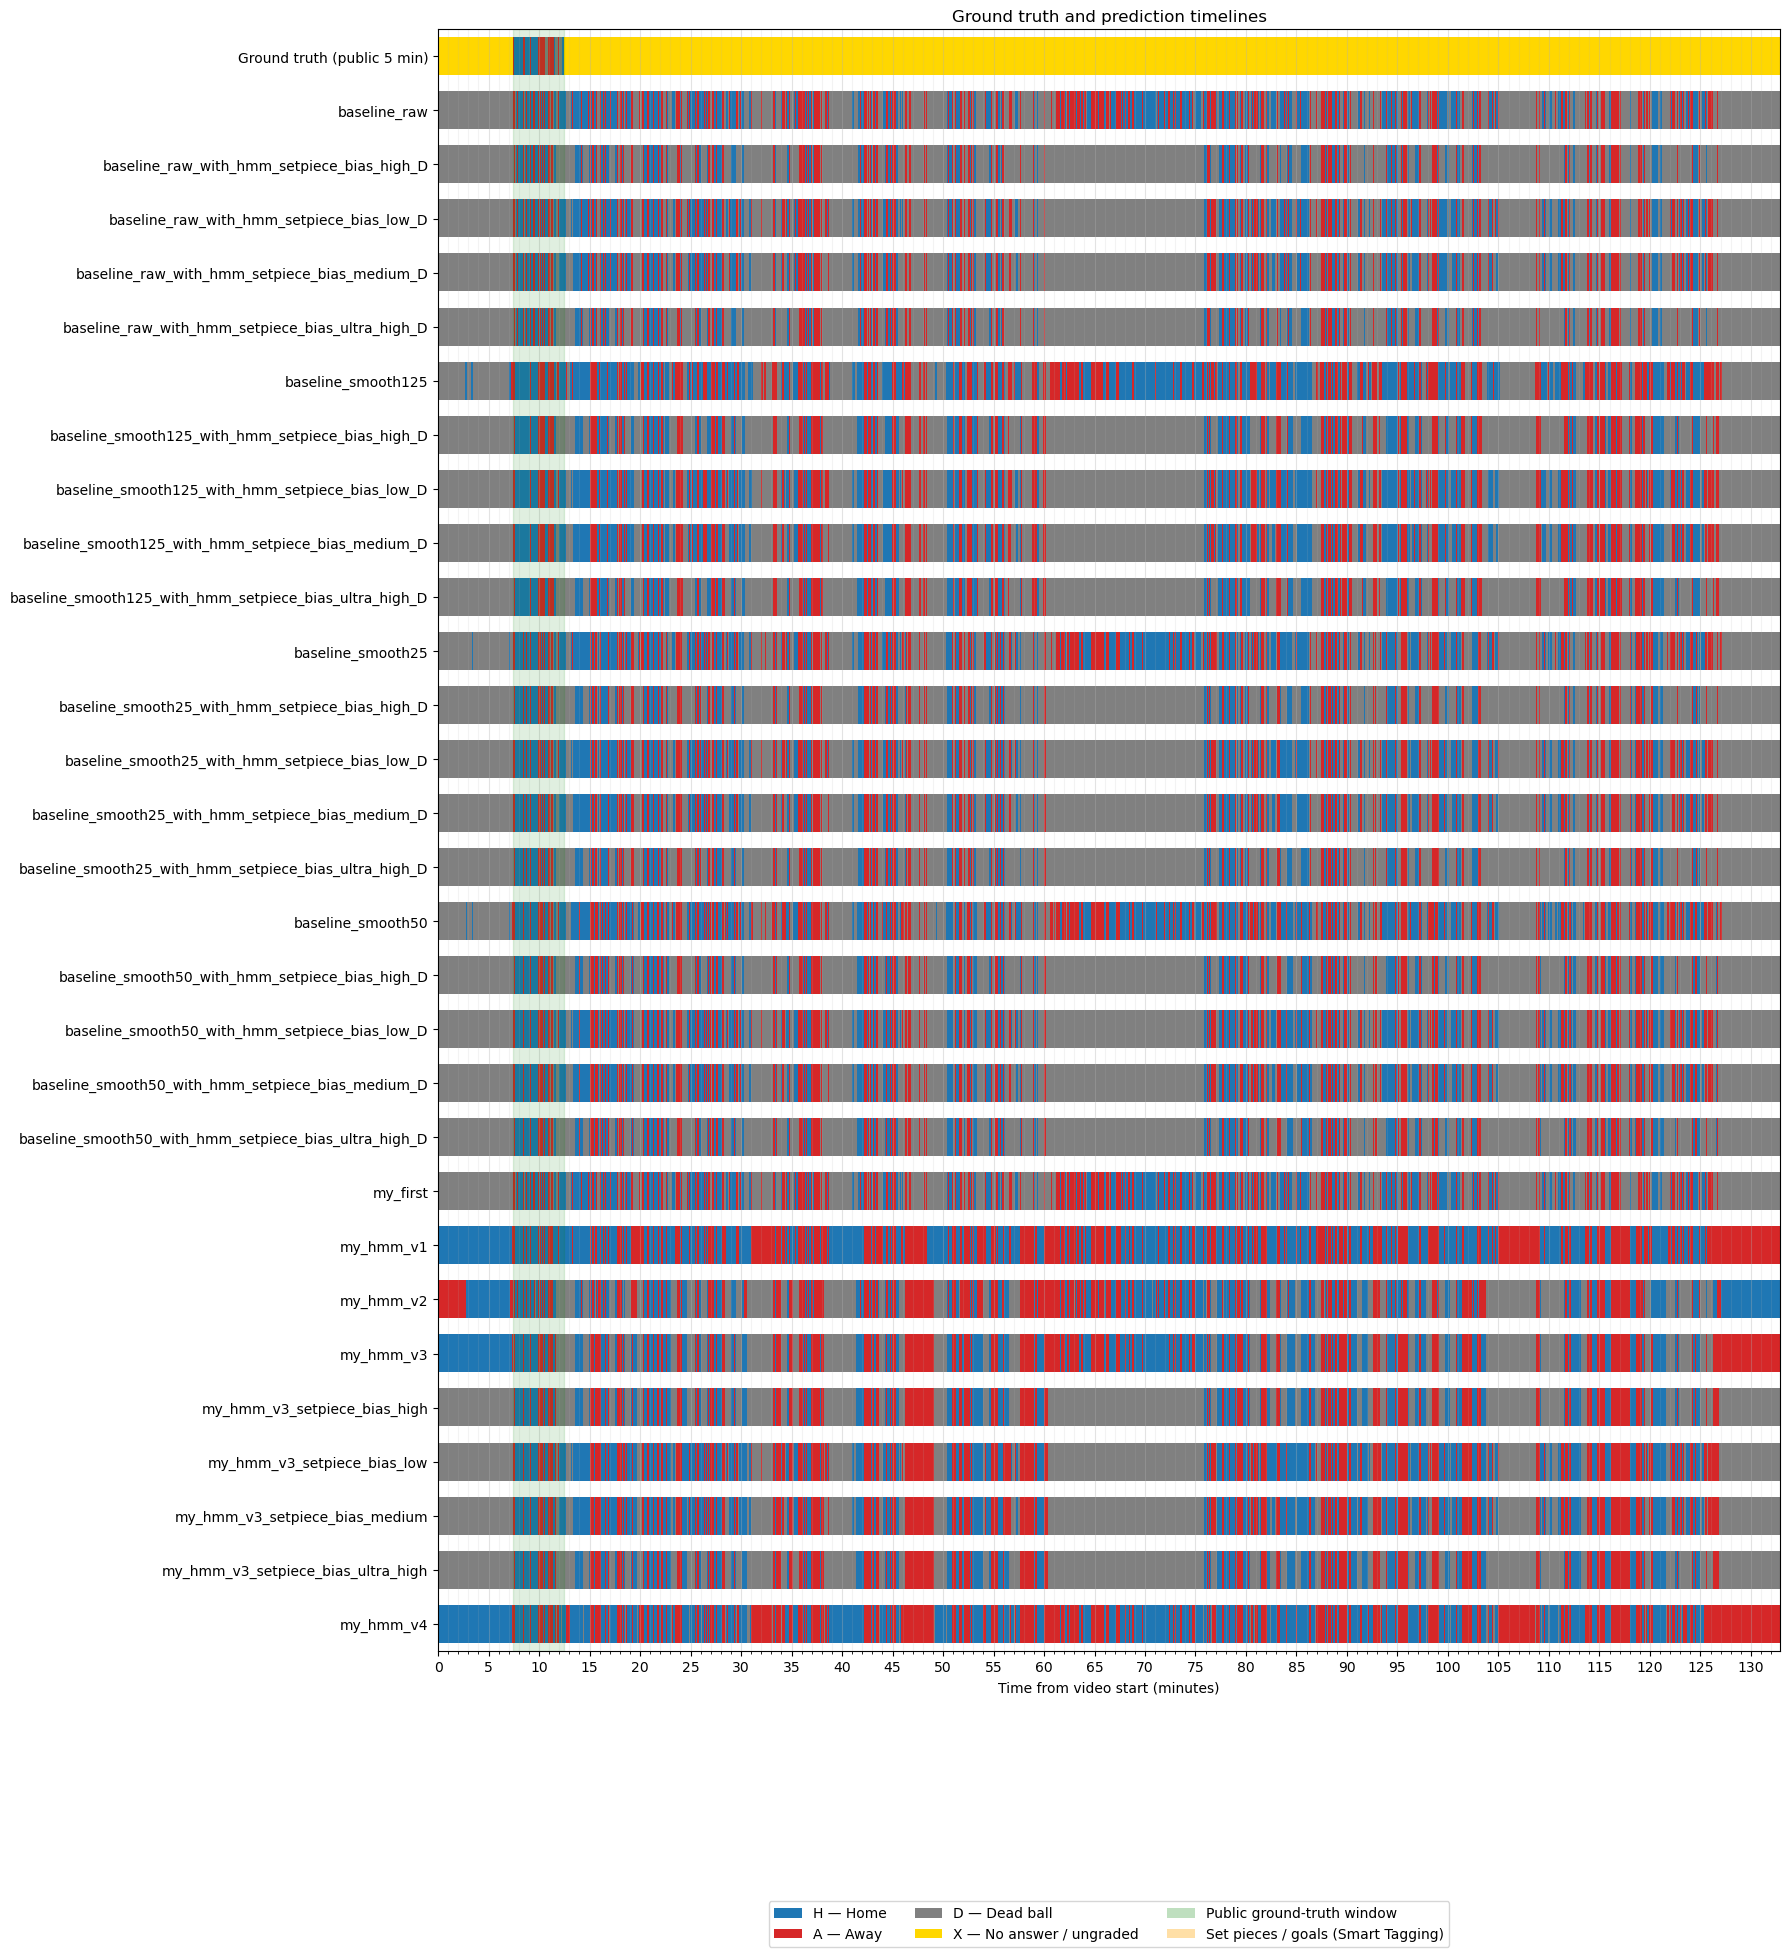

In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator
from kloppy import sportscode
import games

results_dir = Path("../evaluation/results")
gt_path = Path("../evaluation/gt/BAR-ATH_possession_gt_public.csv")

label_to_code = {"H": 0, "A": 1, "D": 2, "X": 3}
label_colors = {"H": "tab:blue", "A": "tab:red", "D": "gray", "X": "gold"}

# Load the full-length public ground truth. Ungraded frames are X.
gt = pd.read_csv(gt_path).sort_values("frame")
if not np.array_equal(gt["frame"].to_numpy(), np.arange(len(gt))):
    raise ValueError("Ground-truth frames must run consecutively from 0.")

gt_unknown = set(gt["label"].dropna()) - set(label_to_code)
if gt_unknown or gt["label"].isna().any():
    raise ValueError(f"Unexpected or missing ground-truth labels: {gt_unknown}")

models = [("Ground truth (public 5 min)", gt["label"].map(label_to_code).to_numpy())]

# Add each prediction CSV, skipping the diagnostic trace file.
for path in sorted(results_dir.glob("*.csv")):
    if "trace" in path.stem.lower():
        continue

    df = pd.read_csv(path)
    if not {"frame", "label"}.issubset(df.columns):
        continue

    df = df.sort_values("frame")
    if not np.array_equal(df["frame"].to_numpy(), np.arange(len(df))):
        raise ValueError(f"{path.name}: frames must run consecutively from 0.")

    unknown = set(df["label"].dropna()) - set(label_to_code)
    if unknown or df["label"].isna().any():
        raise ValueError(f"{path.name}: unexpected or missing labels: {unknown}")

    models.append((path.stem, df["label"].map(label_to_code).to_numpy()))

frame_counts = {len(codes) for _, codes in models}
if len(frame_counts) != 1:
    raise ValueError("Ground truth and model CSVs have different numbers of frames.")

n_frames = frame_counts.pop()
fps = 25
duration_min = n_frames / fps / 60
cmap = ListedColormap([label_colors[label] for label in label_to_code])

fig, ax = plt.subplots(figsize=(18, max(4, 0.65 * len(models))))

for row, (name, codes) in enumerate(models):
    ax.imshow(
        codes[np.newaxis, :],
        aspect="auto",
        interpolation="nearest",
        extent=[0, duration_min, row - 0.35, row + 0.35],
        cmap=cmap,
        vmin=-0.5,
        vmax=3.5,
    )

# Overlay Smart Tagging set-piece and goal intervals.
tags = sportscode.load(games.asset_paths()["smart_tagging"]).to_df()
restart_tags = tags[tags["code"].isin(["SET PIECES", "GOALS"])]

'''
for _, tag in restart_tags.iterrows():
    start = max(0, int(round(tag["timestamp"].total_seconds() * fps)))
    end = min(n_frames, int(round(tag["end_timestamp"].total_seconds() * fps)))

    if start < end:
        ax.axvspan(
            start / fps / 60,
            end / fps / 60,
            color="orange",
            alpha=0.18,
            zorder=2,
        )
'''
        
# Highlight the five-minute public ground-truth interval.
ax.axvspan(
    11185 / fps / 60,
    18685 / fps / 60,
    color="green",
    alpha=0.12,
    zorder=2,
)

ax.set_xlim(0, duration_min)
ax.set_ylim(len(models) - 0.5, -0.5)
ax.set_yticks(range(len(models)))
ax.set_yticklabels([name for name, _ in models])
ax.set_xlabel("Time from video start (minutes)")
ax.set_title("Ground truth and prediction timelines")

ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.grid(axis="x", which="major", alpha=0.35)
ax.grid(axis="x", which="minor", alpha=0.15)

present = sorted(
    {
        label
        for _, codes in models
        for label, code in label_to_code.items()
        if np.any(codes == code)
    },
    key=lambda label: label_to_code[label],
)
handles = [
    Patch(
        facecolor=label_colors[label],
        label=f"{label} — " + {
            "H": "Home",
            "A": "Away",
            "D": "Dead ball",
            "X": "No answer / ungraded",
        }[label],
    )
    for label in present
]
handles.extend([
    Patch(facecolor="green", alpha=0.25, label="Public ground-truth window"),
    Patch(facecolor="orange", alpha=0.35, label="Set pieces / goals (Smart Tagging)"),
])
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)

plt.tight_layout()
plt.show()

Ultra high and high biases have two big gaps in places where Dead ball is (compared visually first 5 minuts to their prediction). Despite very good metrics they will perform very poorly

Also for the whole match baseline smooth 50 performs the best (info from my markdown written above)

Plotting same things, but without high and ultra high:

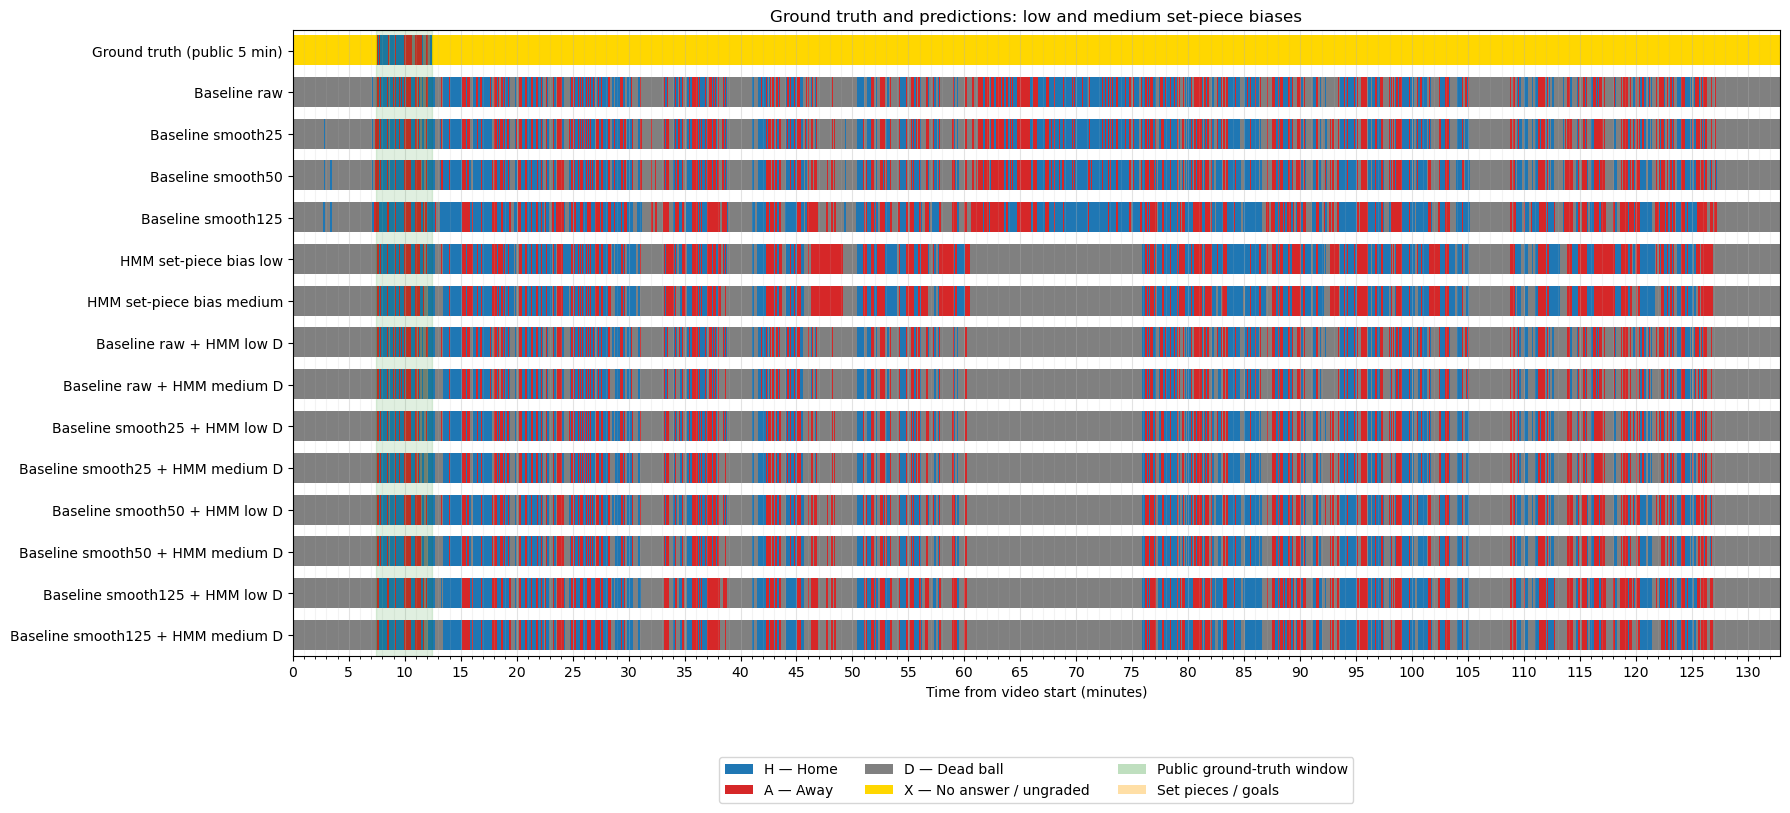

In [18]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator
from kloppy import sportscode
import games

results_dir = Path("../evaluation/results")
gt_path = Path("../evaluation/gt/BAR-ATH_possession_gt_public.csv")

# Include baselines, low/medium HMMs, and low/medium baseline + HMM-D combinations.
files = {
    "Baseline raw": results_dir / "baseline_raw.csv",
    "Baseline smooth25": results_dir / "baseline_smooth25.csv",
    "Baseline smooth50": results_dir / "baseline_smooth50.csv",
    "Baseline smooth125": results_dir / "baseline_smooth125.csv",
    "HMM set-piece bias low": results_dir / "my_hmm_v3_setpiece_bias_low.csv",
    "HMM set-piece bias medium": results_dir / "my_hmm_v3_setpiece_bias_medium.csv",
}

for baseline_name in ["raw", "smooth25", "smooth50", "smooth125"]:
    for bias in ["low", "medium"]:
        files[f"Baseline {baseline_name} + HMM {bias} D"] = (
            results_dir
            / f"baseline_{baseline_name}_with_hmm_setpiece_bias_{bias}_D.csv"
        )

missing = [str(path) for path in files.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Run the cells that generate these files first:\n" + "\n".join(missing)
    )

label_to_code = {"H": 0, "A": 1, "D": 2, "X": 3}
label_colors = {"H": "tab:blue", "A": "tab:red", "D": "gray", "X": "gold"}

# Load the public ground truth.
gt = pd.read_csv(gt_path).sort_values("frame")
if not np.array_equal(gt["frame"].to_numpy(), np.arange(len(gt))):
    raise ValueError("Ground-truth frames must run consecutively from 0.")
if gt["label"].isna().any() or set(gt["label"]) - set(label_to_code):
    raise ValueError("Ground truth contains missing or unexpected labels.")

models = [
    ("Ground truth (public 5 min)", gt["label"].map(label_to_code).to_numpy())
]

# Load each selected prediction file.
for name, path in files.items():
    df = pd.read_csv(path).sort_values("frame")

    if not {"frame", "label"}.issubset(df.columns):
        raise ValueError(f"{path.name} must contain 'frame' and 'label' columns.")
    if not np.array_equal(df["frame"].to_numpy(), np.arange(len(df))):
        raise ValueError(f"{path.name}: frames must run consecutively from 0.")
    if df["label"].isna().any() or set(df["label"]) - set(label_to_code):
        raise ValueError(f"{path.name}: contains missing or unexpected labels.")

    models.append((name, df["label"].map(label_to_code).to_numpy()))

frame_counts = {len(codes) for _, codes in models}
if len(frame_counts) != 1:
    raise ValueError("Ground truth and prediction files have different frame counts.")

n_frames = frame_counts.pop()
fps = 25
duration_min = n_frames / fps / 60
cmap = ListedColormap([label_colors[label] for label in label_to_code])

fig, ax = plt.subplots(figsize=(18, max(5, 0.55 * len(models))))

for row, (_, codes) in enumerate(models):
    ax.imshow(
        codes[np.newaxis, :],
        aspect="auto",
        interpolation="nearest",
        extent=[0, duration_min, row - 0.35, row + 0.35],
        cmap=cmap,
        vmin=-0.5,
        vmax=3.5,
    )

# Overlay Smart Tagging set-piece and goal intervals.
tags = sportscode.load(games.asset_paths()["smart_tagging"]).to_df()
restart_tags = tags[tags["code"].isin(["SET PIECES", "GOALS"])]

for _, tag in restart_tags.iterrows():
    start = max(0, int(round(tag["timestamp"].total_seconds() * fps)))
    end = min(n_frames, int(round(tag["end_timestamp"].total_seconds() * fps)))


'''
    if start < end:
        ax.axvspan(
            start / fps / 60,
            end / fps / 60,
            color="orange",
            alpha=0.18,
            zorder=2,
        )
'''
        

# Shade the public ground-truth interval.
ax.axvspan(
    11185 / fps / 60,
    18685 / fps / 60,
    color="green",
    alpha=0.12,
    zorder=2,
)

ax.set_xlim(0, duration_min)
ax.set_ylim(len(models) - 0.5, -0.5)
ax.set_yticks(range(len(models)))
ax.set_yticklabels([name for name, _ in models])
ax.set_xlabel("Time from video start (minutes)")
ax.set_title("Ground truth and predictions: low and medium set-piece biases")

ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.grid(axis="x", which="major", alpha=0.35)
ax.grid(axis="x", which="minor", alpha=0.15)

legend_labels = [
    Patch(facecolor=label_colors[label], label=f"{label} — {description}")
    for label, description in [
        ("H", "Home"),
        ("A", "Away"),
        ("D", "Dead ball"),
        ("X", "No answer / ungraded"),
    ]
]
legend_labels.extend([
    Patch(facecolor="green", alpha=0.25, label="Public ground-truth window"),
    Patch(facecolor="orange", alpha=0.35, label="Set pieces / goals"),
])

ax.legend(
    handles=legend_labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
)

plt.tight_layout()
plt.show()

## Base on the plot, Baseline smooth 50 + HMM low D perform most closly to a ground truth, respecting global occurance of Dead ball